In [1]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from collections import OrderedDict

# Loading the data

The data is quite large. It helps to pre-define a schema, so Polars knows how to handle each column. I got the following schema after a first-pass loading.

In [2]:
# pre-defining the schema massively improves read times.
df_schema = OrderedDict(
    [
        ("Run", pl.String),
        ("ReleaseDate", pl.String),
        ("LoadDate", pl.String),
        ("spots", pl.Int64),
        ("bases", pl.Int64),
        ("spots_with_mates", pl.Int64),
        ("avgLength", pl.Float64),
        ("size_MB", pl.Int64),
        ("AssemblyName", pl.String),
        ("download_path", pl.String),
        ("Experiment", pl.String),
        ("LibraryName", pl.String),
        ("LibraryStrategy", pl.String),
        ("LibrarySelection", pl.String),
        ("LibrarySource", pl.String),
        ("LibraryLayout", pl.String),
        ("InsertSize", pl.Int64),
        ("InsertDev", pl.Float64),
        ("Platform", pl.String),
        ("Model", pl.String),
        ("SRAStudy", pl.String),
        ("BioProject", pl.String),
        ("Study_Pubmed_id", pl.String),
        ("ProjectID", pl.String),
        ("Sample", pl.String),
        ("BioSample", pl.String),
        ("SampleType", pl.String),
        ("TaxID", pl.String),
        ("ScientificName", pl.String),
        ("SampleName", pl.String),
        ("g1k_pop_code", pl.String),
        ("source", pl.String),
        ("g1k_analysis_group", pl.String),
        ("Subject_ID", pl.String),
        ("Sex", pl.String),
        ("Disease", pl.String),
        ("Tumor", pl.String),
        ("Affection_Status", pl.String),
        ("Analyte_Type", pl.String),
        ("Histological_Type", pl.String),
        ("Body_Site", pl.String),
        ("CenterName", pl.String),
        ("Submission", pl.String),
        ("dbgap_study_accession", pl.String),
        ("Consent", pl.String),
        ("RunHash", pl.String),
        ("ReadHash", pl.String),
    ]
)

In [4]:
df = pl.read_csv(
    "resources/runinfo.csv",
    n_threads=12,
    batch_size=65536,
    schema=df_schema,
    ignore_errors=True,
)

We get the following columns:

In [5]:
df.columns

['Run',
 'ReleaseDate',
 'LoadDate',
 'spots',
 'bases',
 'spots_with_mates',
 'avgLength',
 'size_MB',
 'AssemblyName',
 'download_path',
 'Experiment',
 'LibraryName',
 'LibraryStrategy',
 'LibrarySelection',
 'LibrarySource',
 'LibraryLayout',
 'InsertSize',
 'InsertDev',
 'Platform',
 'Model',
 'SRAStudy',
 'BioProject',
 'Study_Pubmed_id',
 'ProjectID',
 'Sample',
 'BioSample',
 'SampleType',
 'TaxID',
 'ScientificName',
 'SampleName',
 'g1k_pop_code',
 'source',
 'g1k_analysis_group',
 'Subject_ID',
 'Sex',
 'Disease',
 'Tumor',
 'Affection_Status',
 'Analyte_Type',
 'Histological_Type',
 'Body_Site',
 'CenterName',
 'Submission',
 'dbgap_study_accession',
 'Consent',
 'RunHash',
 'ReadHash']

Only a subset of those are "interesting" to me, so I subset:

In [6]:
# select the interesting cols
cols_to_select = [
    "Run",
    "ReleaseDate",
    "LoadDate",
    "spots",
    "bases",
    "spots_with_mates",
    "avgLength",
    "size_MB",
    "LibraryStrategy",
    "LibrarySelection",
    "LibrarySource",
    "LibraryLayout",
    "Platform",
    "Model",
    "SampleType",
    "TaxID",
    "ScientificName",
    "SampleName",
    "Sex",
    "Disease",
]

In [7]:
df = df.select(pl.col(cols_to_select))

Then, I manipulate the dates to a format that I like. First, we convert string to true Date format. Then, for plotting, I convert year + date into year + 1/12 fraction of year * months.

In [8]:
# cast str to Datetime
df = df.with_columns(
    pl.col("ReleaseDate")
    .str.strptime(pl.Date, format="%Y-%m-%d %H:%M:%S", strict=False)
    .cast(pl.Datetime)
)
df = df.with_columns(
    pl.col("LoadDate")
    .str.strptime(pl.Date, format="%Y-%m-%d %H:%M:%S", strict=False)
    .cast(pl.Datetime)
)
# convert date format into a plottable YYYY.MM format where MM is equal to the 0-based fraction of the year that each month represents
df = df.with_columns(pl.col("ReleaseDate").dt.strftime("%b").alias("ReleaseDateMonth"))
df = df.with_columns(pl.col("ReleaseDate").dt.strftime("%Y").alias("ReleaseDateYear"))
df = df.with_columns(
    (
        pl.col("ReleaseDate").dt.year()
        + (pl.col("ReleaseDate").dt.month() / 12)
        - (
            1 / 12
        )  # Subtracting (1/12) to start months at 0 (January as 0/12, February as 1/12, etc.)
    ).alias("ReleaseDate_YM")
)

# Plotting

In [12]:
def plot_cumsum(df, vars_groupby, vars_toplot):
    for var_groupby in vars_groupby:
        for var_toplot in vars_toplot:
            df_groupby = (
                df.group_by(["ReleaseDate_YM", var_groupby])
                .agg([pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")])
                .sort(["ReleaseDate_YM", var_groupby])
            )

            # first compute the cumulative sum within each group
            df_groupby = df_groupby.group_by(var_groupby).map_groups(
                lambda group_df: group_df.with_columns(
                    pl.col(f"{var_toplot}_sum").cum_sum().alias(f"{var_toplot}_cumsum")
                )
            )

            # need to sort by 'ReleaseDate_YM' after the grouping operation
            df_groupby = df_groupby.sort(["ReleaseDate_YM", var_groupby])
            df_groupby = df_groupby.drop_nulls()

            fig, ax = plt.subplots()

            sns.lineplot(
                data=df_groupby.to_pandas(),  # Convert to Pandas DataFrame for seaborn compatibility
                x="ReleaseDate_YM",
                y=f"{var_toplot}_cumsum",
                ax=ax,
                hue=var_groupby,
            )

            ax.set_xticks(range(2007, 2025, 1))
            ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
            ax.set_yscale("log")

            # now let's start adding labels to each of these lines.
            # first i need to know the maximum value achieved
            df_max_cumsum = df_groupby.group_by(var_groupby).agg(
                [pl.col(f"{var_toplot}_cumsum").max().alias(f"{var_toplot}_cumsum_max")]
            )

            # then iterate over the rows of this polars df
            for var_groupby_value, max_val in df_max_cumsum.iter_rows():
                # Find the ReleaseDate_YM corresponding to this max_cumsum for the current model
                max_x = df_groupby.select(pl.col("ReleaseDate_YM").max()).to_numpy()[0][
                    0
                ]

                # Draw the label on the plot
                ax.text(
                    max_x,
                    max_val,
                    var_groupby_value,
                    horizontalalignment="left",
                    verticalalignment="center",
                )

            plt.legend(loc=(1.04, 0))
            plt.show()

/tmp/ipykernel_1631640/4285574583.py:59: DeprecationWarning: `apply` is deprecated. It has been renamed to `map_elements`.
  .then(pl.col(var_groupby).apply(lambda x: sorted_platforms.index(x)))


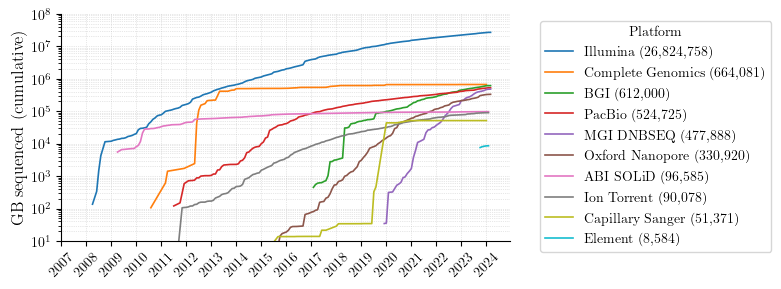

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

import matplotlib
matplotlib.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "axes.labelsize": 12,
        "axes.titlesize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "grid.alpha": 0.6,
        "axes.grid": True,
        "lines.linewidth": 1.2,
        "lines.markeredgewidth": 0.5,
    }
)

def plot_cumsum(df, vars_groupby, vars_toplot):
    fig, ax = plt.subplots(figsize=(8, 3))

    for var_groupby in vars_groupby:
        for var_toplot in vars_toplot:
            df = df.with_columns(pl.col(var_toplot) / 1000)
            df_groupby = (
                df.group_by(["ReleaseDate_YM", var_groupby])
                .agg([pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")])
                .sort(["ReleaseDate_YM", var_groupby])
            )

            df_groupby = df_groupby.group_by(var_groupby).map_groups(
                lambda group_df: group_df.with_columns(
                    pl.col(f"{var_toplot}_sum").cum_sum().alias(f"{var_toplot}_cumsum")
                )
            )

            df_groupby = df_groupby.sort(["ReleaseDate_YM", var_groupby])
            df_groupby = df_groupby.drop_nulls()

            total_counts = (
                df_groupby.select(var_groupby, f"{var_toplot}_cumsum")
                .group_by(var_groupby)
                .max()
                .sort(f"{var_toplot}_cumsum", descending=True)
            )

            sorted_platforms = total_counts[var_groupby].to_list()
            total_counts_dict = total_counts.to_dict()

            df_groupby = df_groupby.with_columns(
                pl.col(var_groupby).cast(pl.Categorical)
            )
            df_groupby = df_groupby.sort(
                pl.when(pl.col(var_groupby).is_in(sorted_platforms))
                .then(pl.col(var_groupby).apply(lambda x: sorted_platforms.index(x)))
                .otherwise(len(sorted_platforms))
            )

            legend_labels = {
                group: f"{group} ({int(total_counts_dict[f'{var_toplot}_cumsum'][i]):,})"
                for i, group in enumerate(sorted_platforms)
            }

            sns.lineplot(
                data=df_groupby,
                x="ReleaseDate_YM",
                y=f"{var_toplot}_cumsum",
                ax=ax,
                hue=var_groupby,
                hue_order=sorted_platforms,
            )

            ax.set_xticks(range(2007, 2025, 1))
            ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
            ax.set_yscale("log")
            ax.set_xlabel("")
            ax.set_ylabel("GB sequenced (cumulative)")
            ax.set_ylim([10, 100000000])

            handles, labels = ax.get_legend_handles_labels()
            new_labels = [legend_labels[label] for label in labels]
            ax.legend(handles, new_labels, title=var_groupby, bbox_to_anchor=(1.05, 1), loc="upper left")

            plt.grid(True, which="both", linestyle="dotted", linewidth=0.5)
            plt.gca().spines["top"].set_visible(False)
            plt.gca().spines["right"].set_visible(False)
            plt.tight_layout()

            plt.savefig("figs/plot_geo.svg", format="svg")
            plt.savefig("figs/plot_geo.png")
            plt.savefig("figs/plot_geo.pgf")

            plt.show()

df = df.filter(pl.col("Platform") != "GENEMIND")
df = df.filter(pl.col("Platform") != "VELA_DIAGNOSTICS")
df = df.filter(pl.col("Platform") != "TAPESTRI")
df = df.filter(pl.col("Platform") != "GENAPSYS")
df = df.filter(pl.col("Platform") != "HELICOS")
df = df.filter(pl.col("Platform") != "LS454")

platform_aliases = {
    "COMPLETE_GENOMICS": "Complete Genomics",
    "ILLUMINA": "Illumina",
    "PACBIO_SMRT": "PacBio",
    "OXFORD_NANOPORE": "Oxford Nanopore",
    "BGISEQ": "BGI",
    "DNBSEQ": "MGI DNBSEQ",
    "ION_TORRENT": "Ion Torrent",
    "CAPILLARY": "Capillary Sanger",
    "ELEMENT": "Element",
    "ABI_SOLID": "ABI SOLiD"
}
df = df.with_columns(
    pl.col("Platform").replace(platform_aliases)
)

plot_cumsum(df, ["Platform"], ["size_MB"])
